In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn import metrics

In [2]:
plt.style.use('fivethirtyeight')

In [3]:
df = pd.read_csv('drug_classification.csv')
df

,Age,Sex,BP,Cholesterol,Na_to_K,Drug_Type
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY
...,...,...,...,...,...,...
195,56,F,LOW,HIGH,11.567,drugC
196,16,M,LOW,HIGH,12.006,drugC
197,52,M,NORMAL,HIGH,9.894,drugX
198,23,M,NORMAL,NORMAL,14.020,drugX


In [4]:
df.columns

Index(['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K', 'Drug_Type'], dtype='object')

In [5]:
df.rename(columns={'Sex': 'Gender'}, inplace=True)
df.columns

Index(['Age', 'Gender', 'BP', 'Cholesterol', 'Na_to_K', 'Drug_Type'], dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Gender       200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug_Type    200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


In [7]:
for col in df:
    print(f"{col}: {df[col].unique()}\n")

Age: [23 47 28 61 22 49 41 60 43 34 74 50 16 69 32 57 63 48 33 31 39 45 18 65
 53 46 15 73 58 66 37 68 67 62 24 26 40 38 29 17 54 70 36 19 64 59 51 42
 56 20 72 35 52 55 30 21 25]

Gender: ['F' 'M']

BP: ['HIGH' 'LOW' 'NORMAL']

Cholesterol: ['HIGH' 'NORMAL']

Na_to_K: [25.355 13.093 10.114  7.798 18.043  8.607 16.275 11.037 15.171 19.368
 11.767 19.199 15.376 20.942 12.703 15.516 11.455 13.972  7.298 25.974
 19.128 25.917 30.568 15.036 33.486 18.809 30.366  9.381 22.697 17.951
  8.75   9.567 11.014 31.876 14.133  7.285  9.445 13.938  9.709  9.084
 19.221 14.239 15.79  12.26  12.295  8.107 13.091 10.291 31.686 19.796
 19.416 10.898 27.183 18.457 10.189 14.16  11.34  27.826 10.091 18.703
 29.875  9.475 20.693  8.37  13.303 27.05  12.856 10.832 24.658 24.276
 13.967 19.675 10.605 22.905 17.069 20.909 11.198 19.161 13.313 10.84
 13.934  7.761  9.712 11.326 10.067 13.935 13.597 15.478 23.091 17.211
 16.594 15.156 29.45  29.271 15.015 11.424 38.247 25.395 35.639 16.725
 11.871 12.854 13.127

In [8]:
df.duplicated().sum()

0

In [9]:
categorical = df.select_dtypes(['object'])
for var in categorical:
    print(f'{var} contains {df[var].nunique()} labels.')
    print(df[var].value_counts())
    print('-' * 30)

Gender contains 2 labels.
Gender
M    104
F     96
Name: count, dtype: int64
------------------------------
BP contains 3 labels.
BP
HIGH      77
LOW       64
NORMAL    59
Name: count, dtype: int64
------------------------------
Cholesterol contains 2 labels.
Cholesterol
HIGH      103
NORMAL     97
Name: count, dtype: int64
------------------------------
Drug_Type contains 5 labels.
Drug_Type
DrugY    91
drugX    54
drugA    23
drugC    16
drugB    16
Name: count, dtype: int64
------------------------------


In [10]:
df2 = df.copy()
df2['Gender'] = df2['Gender'].map({'M': 0, 'F': 1})
df2['BP'] = df2['BP'].map({'LOW': 0, 'NORMAL': 1, 'HIGH': 2})
df2['Cholesterol'] = df2['Cholesterol'].map({'NORMAL': 0, 'HIGH': 1})
df2['Drug_Type'] = df2['Drug_Type'].map({'DrugY': 0, 'drugX': 1, 'drugA': 2, 'drugC': 3, 'drugB': 4})
df2

,Age,Gender,BP,Cholesterol,Na_to_K,Drug_Type
0,23,1,2,1,25.355,0
1,47,0,0,1,13.093,3
2,47,0,0,1,10.114,3
3,28,1,1,1,7.798,1
4,61,1,0,1,18.043,0
...,...,...,...,...,...,...
195,56,1,0,1,11.567,3
196,16,0,0,1,12.006,3
197,52,0,1,1,9.894,1
198,23,0,1,0,14.020,1


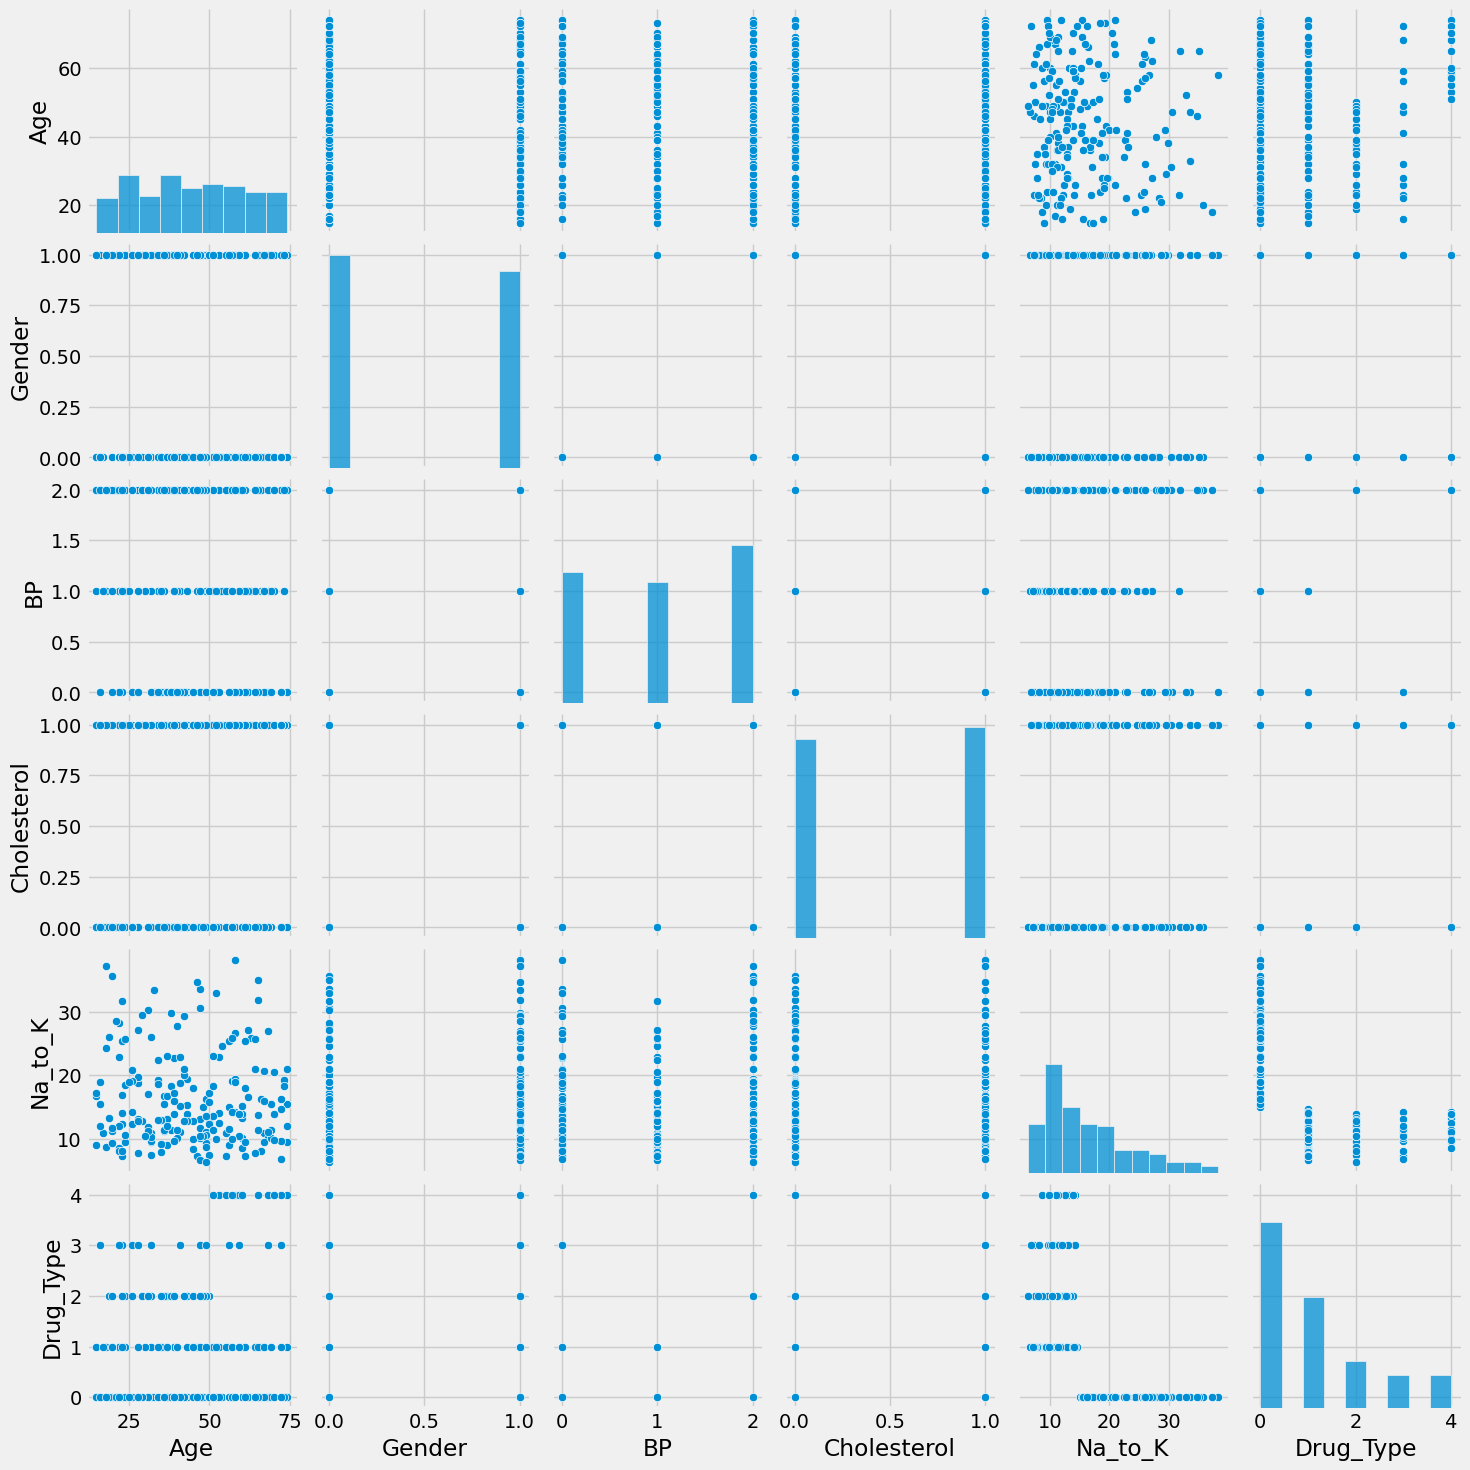

In [11]:
sns.pairplot(df2)
plt.show()

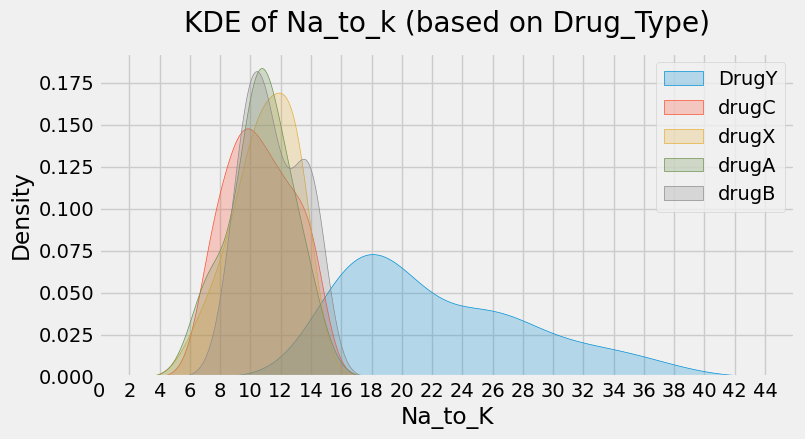

In [12]:
plt.figure(figsize=(8, 4))
for i, label in enumerate(df.Drug_Type.unique().tolist()):
    sns.kdeplot(df2.loc[df2['Drug_Type'] == i, 'Na_to_K'], label=label, fill=True)
plt.title('KDE of Na_to_k (based on Drug_Type)', pad=15)
plt.xticks(np.arange(0, 46, 2))
plt.xlim([0, 46])
plt.legend()
plt.show()

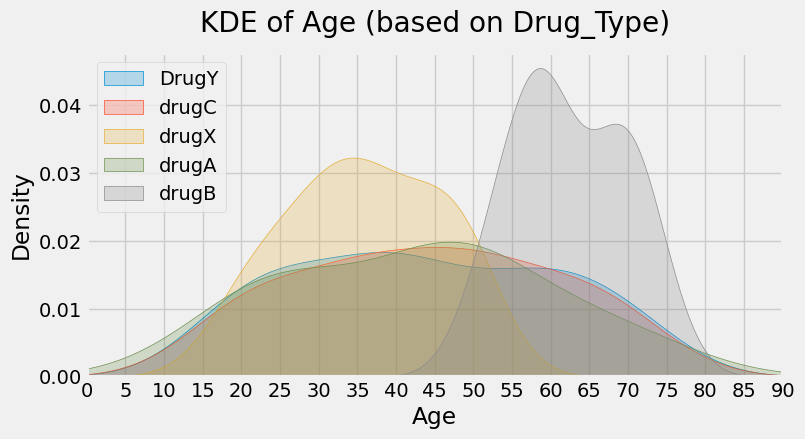

In [13]:
plt.figure(figsize=(8, 4))
for i, label in enumerate(df.Drug_Type.unique().tolist()):
    sns.kdeplot(df2.loc[df2['Drug_Type'] == i, 'Age'], label=label, fill=True)
plt.title('KDE of Age (based on Drug_Type)', pad=15)
plt.xticks(np.arange(0, 91, 5))
plt.xlim([0, 90])
plt.legend()
plt.show()

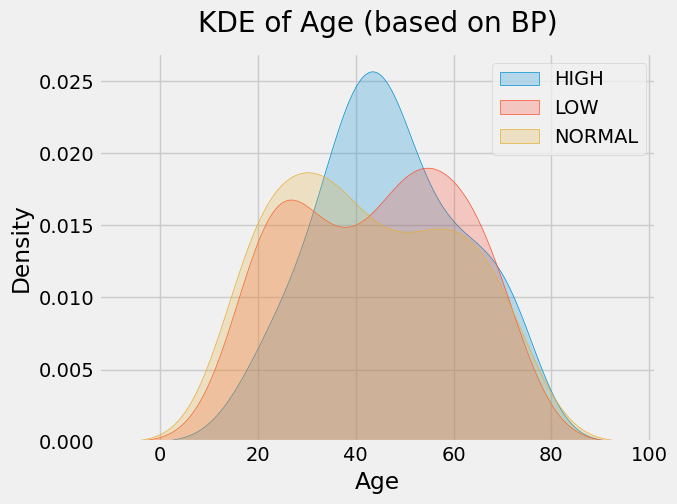

In [14]:
for i, label in enumerate(df.BP.unique().tolist()):
    sns.kdeplot(df2.loc[df2['BP'] == i, 'Age'], label=label, fill=True)
plt.title('KDE of Age (based on BP)', pad=15)
plt.legend()
plt.show()

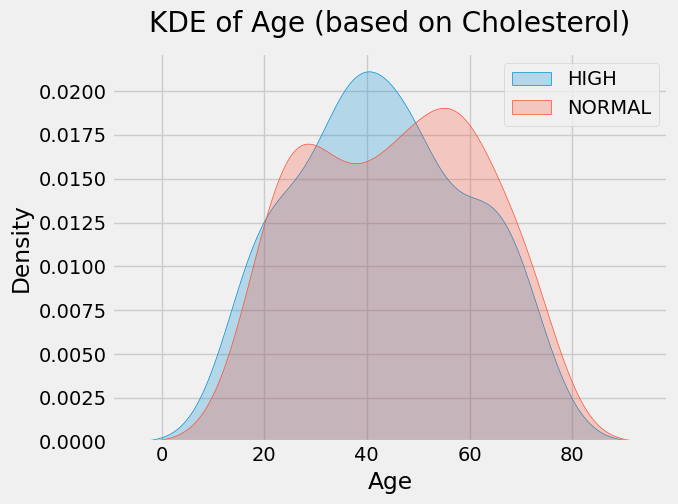

In [15]:
for i, label in enumerate(df.Cholesterol.unique().tolist()):
    sns.kdeplot(df2.loc[df2['Cholesterol'] == i, 'Age'], label=label, fill=True)
plt.title('KDE of Age (based on Cholesterol)', pad=15)
plt.legend()
plt.show()

In [16]:
df2.describe().round(3).T

,count,mean,std,min,25%,50%,75%,max
Age,200.0,44.315,16.544,15.000,31.000,45.000,58.00,74.000
Gender,200.0,0.480,0.501,0.000,0.000,0.000,1.00,1.000
BP,200.0,1.065,0.839,0.000,0.000,1.000,2.00,2.000
Cholesterol,200.0,0.515,0.501,0.000,0.000,1.000,1.00,1.000
Na_to_K,200.0,16.084,7.224,6.269,10.446,13.936,19.38,38.247
Drug_Type,200.0,1.060,1.271,0.000,0.000,1.000,2.00,4.000


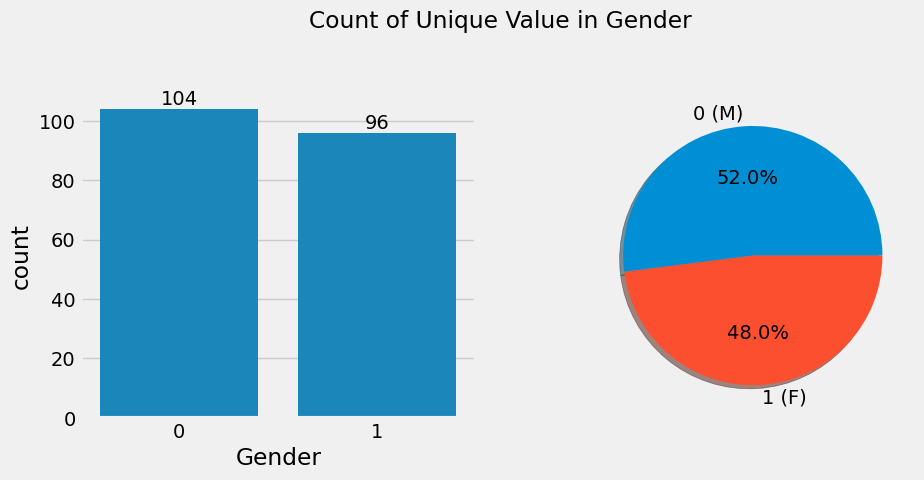

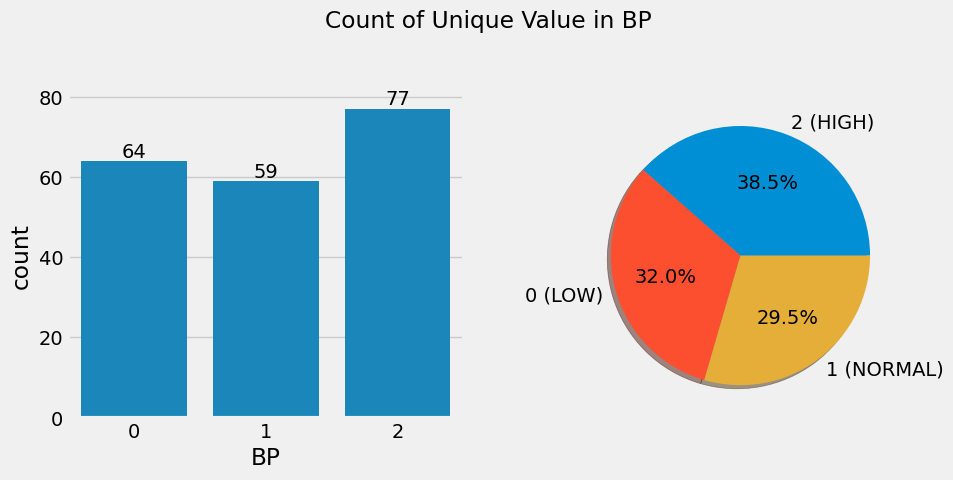

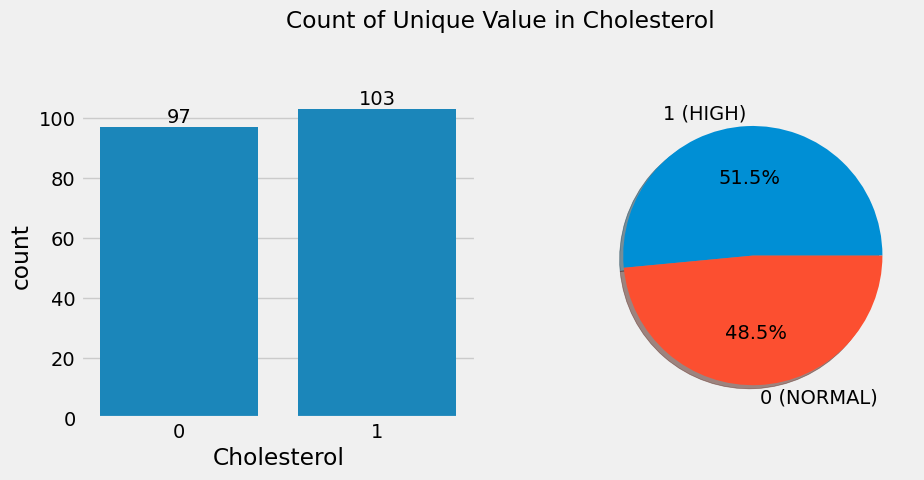

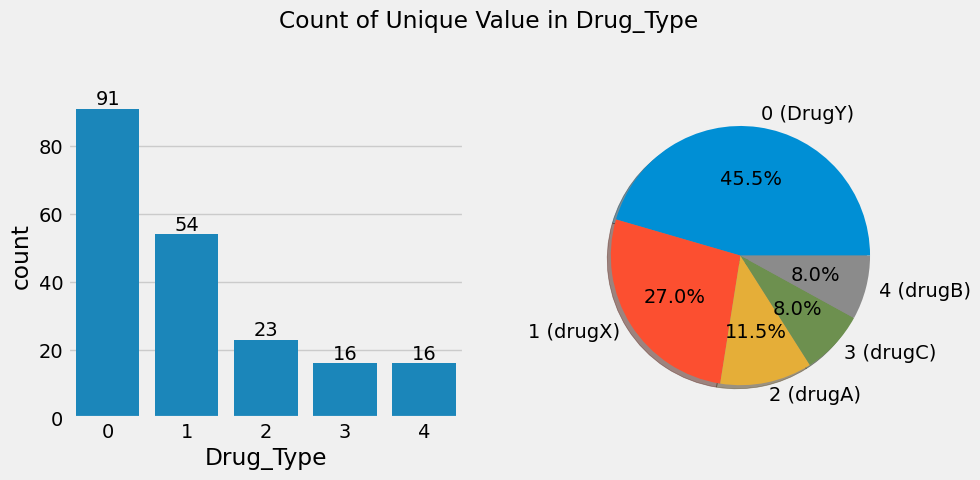

In [17]:
for col in categorical:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    # count of col (countplot)
    sns.countplot(data=df2, x=col, ax=axes[0])

    for container in axes[0].containers:
        axes[0].bar_label(container)

    # count of col (pie chart)
    slices = df2[col].value_counts().values
    activities = [f"{i} ({var})" for i, var in zip(df2[col].value_counts().index, df[col].value_counts().index)]
    axes[1].pie(slices, labels=activities, shadow=True, autopct='%1.1f%%')

    plt.suptitle(f'Count of Unique Value in {col}', y=1.09)
    plt.show()

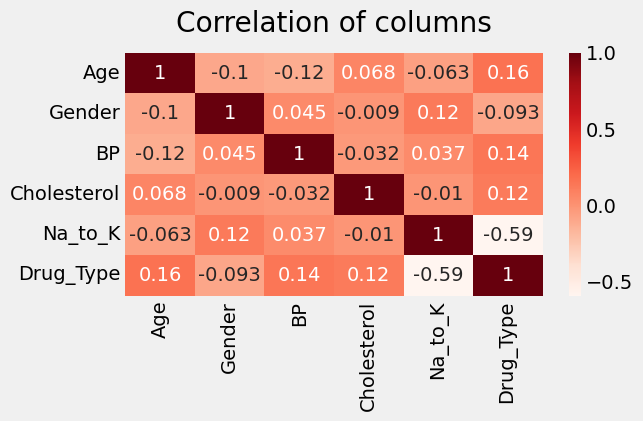

In [18]:
plt.figure(figsize=(6, 3))
sns.heatmap(round(df2.corr(), 3), cmap='Reds', annot=True)
plt.title('Correlation of columns', pad=15)
plt.show()

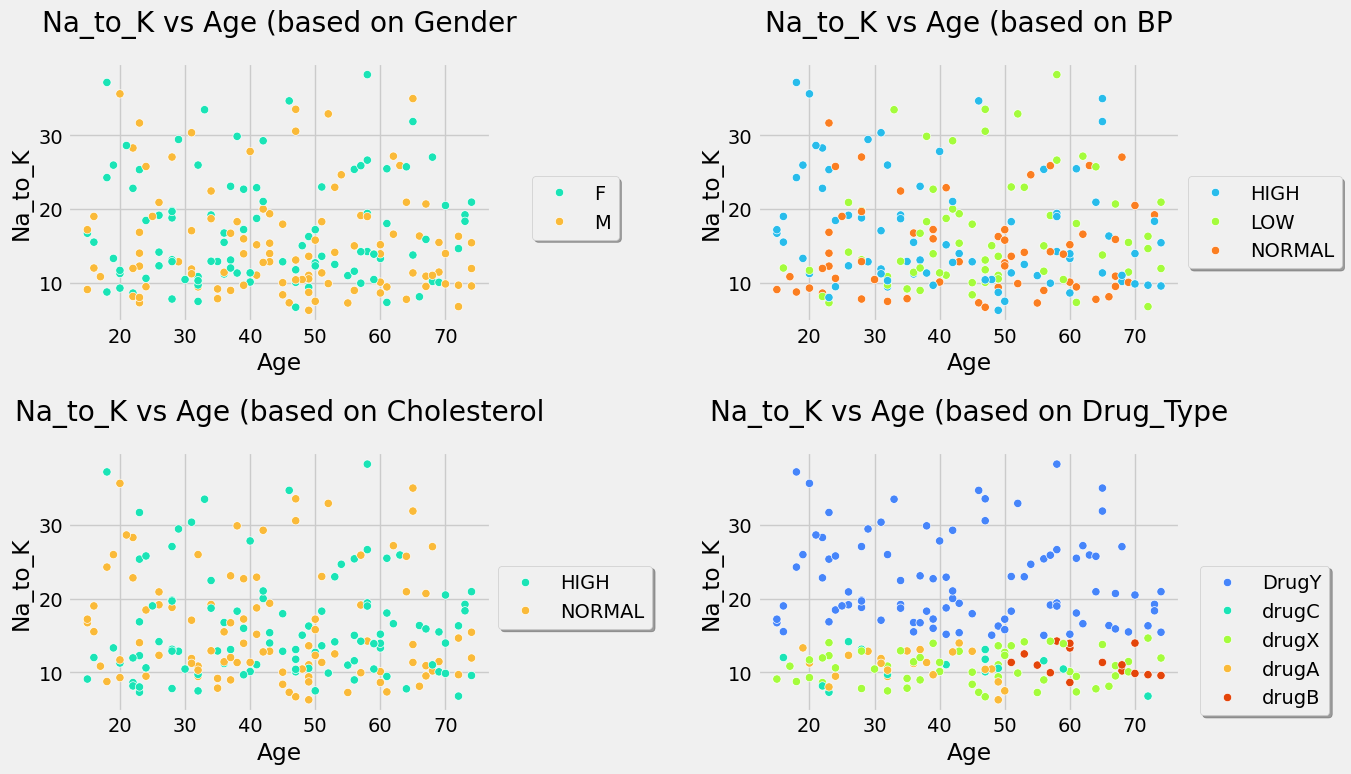

In [19]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for i, col in enumerate(['Gender', 'BP', 'Cholesterol', 'Drug_Type']):
    sns.scatterplot(data=df, x='Age', y='Na_to_K', hue=col, ax=ax[i//2, i % 2], palette='turbo')
    ax[i//2, i % 2].set_title(f'Na_to_K vs Age (based on {col}', y=1.09)
    ax[i//2, i % 2].legend(loc='upper center', bbox_to_anchor=(1.2, 0.6), fancybox=True, shadow=True)

fig.tight_layout()
plt.show()

In [20]:
df3 = df.copy()
df3

,Age,Gender,BP,Cholesterol,Na_to_K,Drug_Type
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY
...,...,...,...,...,...,...
195,56,F,LOW,HIGH,11.567,drugC
196,16,M,LOW,HIGH,12.006,drugC
197,52,M,NORMAL,HIGH,9.894,drugX
198,23,M,NORMAL,NORMAL,14.020,drugX


In [21]:
df2

,Age,Gender,BP,Cholesterol,Na_to_K,Drug_Type
0,23,1,2,1,25.355,0
1,47,0,0,1,13.093,3
2,47,0,0,1,10.114,3
3,28,1,1,1,7.798,1
4,61,1,0,1,18.043,0
...,...,...,...,...,...,...
195,56,1,0,1,11.567,3
196,16,0,0,1,12.006,3
197,52,0,1,1,9.894,1
198,23,0,1,0,14.020,1


In [22]:
df2 = pd.get_dummies(df2, columns=['Gender'], drop_first=True)
df2.head()

,Age,BP,Cholesterol,Na_to_K,Drug_Type,Gender_1
0,23,2,1,25.355,0,True
1,47,0,1,13.093,3,False
2,47,0,1,10.114,3,False
3,28,1,1,7.798,1,True
4,61,0,1,18.043,0,True


In [23]:
scaler = StandardScaler()
df2[['Age', 'Na_to_K']] = scaler.fit_transform(df2[['Age', 'Na_to_K']])

In [24]:
X = df2.drop('Drug_Type', axis=1)
y = df2['Drug_Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [25]:
def classification_full_eval(model, X_train, X_test, y_train, y_test, y_all, model_name='Model'):
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    acc_train = metrics.accuracy_score(y_train, y_train_pred)
    acc_test = metrics.accuracy_score(y_test, y_test_pred)
    recall = metrics.recall_score(y_test, y_test_pred, average='macro')
    precision = metrics.precision_score(y_test, y_test_pred, average='macro')
    f1 = metrics.f1_score(y_test, y_test_pred, average='macro')

    print(f"{model_name} | Train Accuracy: {acc_train:.3f}")
    print(f"{model_name} | Test Accuracy: {acc_test:.3f}")
    print(f"{model_name} | Recall: {recall:.3f}")
    print(f"{model_name} | Precision: {precision:.3f}")
    print(f"{model_name} | F1 Score: {f1:.3f}")

    print(f"\nClassification Report ({model_name}):\n")
    print(metrics.classification_report(y_test, y_test_pred, digits=3))

    cm = metrics.confusion_matrix(y_test, y_test_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Confusion Matrix ({model_name})')
    plt.show()

    n_classes = y_all.nunique()
    y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)
        
        if y_score.ndim == 1:
            y_score = np.vstack([1 - y_score, y_score]).T
    else:
        print("Model has no probability or decision_function output.")
        return

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    plt.figure(figsize=(8, 6))
    for i in range(n_classes):
        fpr[i], tpr[i], _ = metrics.roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = metrics.roc_auc_score(y_test_bin[:, i], y_score[:, i])
        plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC = {roc_auc[i]:.2f})')

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Multi-class ROC Curve ({model_name})')
    plt.legend(loc='lower right')
    plt.show()

In [26]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

Naive Bayes | Train Accuracy: 0.850
Naive Bayes | Test Accuracy: 0.900
Naive Bayes | Recall: 0.956
Naive Bayes | Precision: 0.850
Naive Bayes | F1 Score: 0.880

Classification Report (Naive Bayes):

              precision    recall  f1-score   support

           0      1.000     0.778     0.875        18
           1      1.000     1.000     1.000        11
           2      1.000     1.000     1.000         5
           3      0.500     1.000     0.667         3
           4      0.750     1.000     0.857         3

    accuracy                          0.900        40
   macro avg      0.850     0.956     0.880        40
weighted avg      0.944     0.900     0.908        40



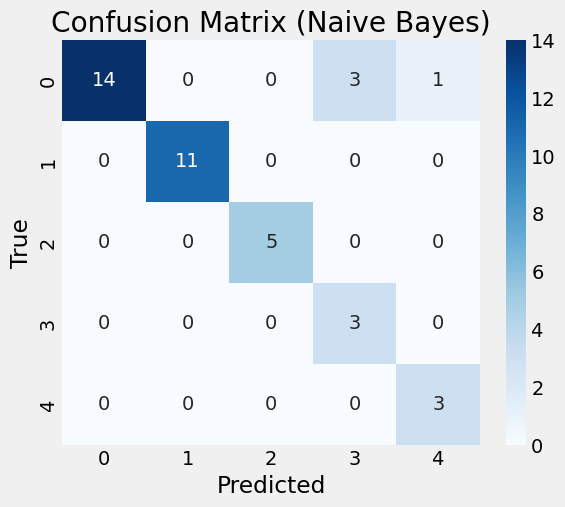

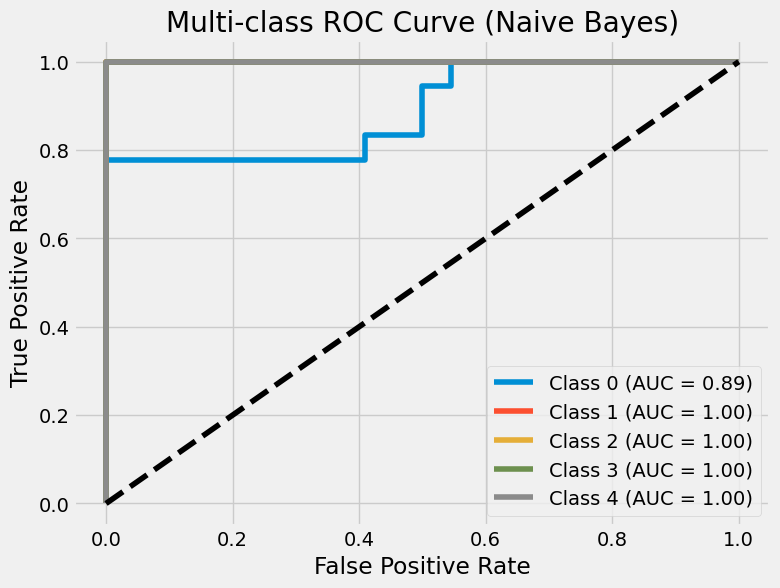

In [27]:
classification_full_eval(GaussianNB(), X_train, X_test, y_train, y_test, y, model_name='Naive Bayes')

Naive Bayes | Train Accuracy: 0.937
Naive Bayes | Test Accuracy: 0.950
Naive Bayes | Recall: 0.949
Naive Bayes | Precision: 0.900
Naive Bayes | F1 Score: 0.915

Classification Report (Naive Bayes):

              precision    recall  f1-score   support

           0      1.000     0.944     0.971        18
           1      1.000     1.000     1.000        11
           2      1.000     0.800     0.889         5
           3      0.750     1.000     0.857         3
           4      0.750     1.000     0.857         3

    accuracy                          0.950        40
   macro avg      0.900     0.949     0.915        40
weighted avg      0.963     0.950     0.952        40



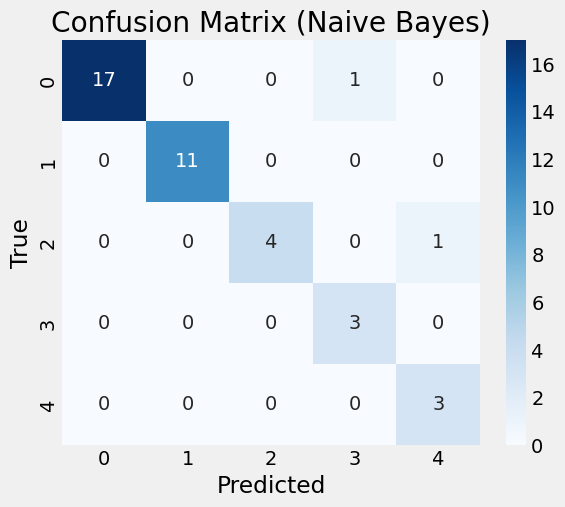

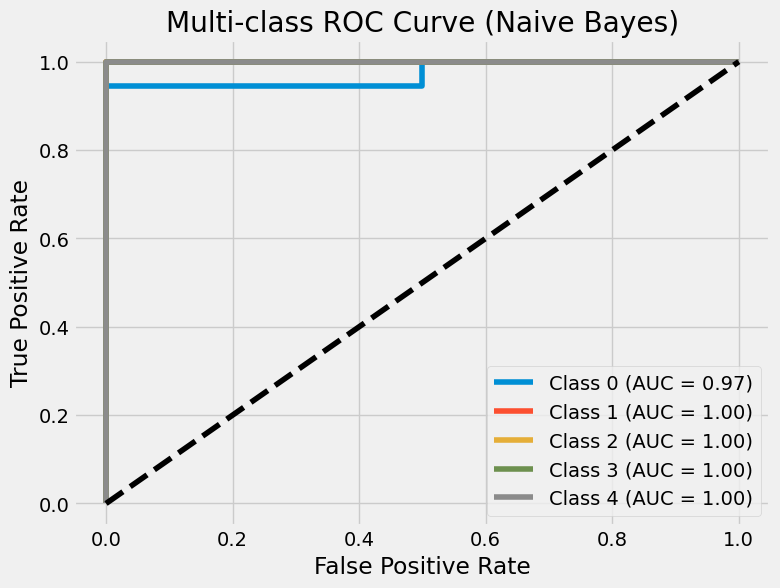

In [28]:
classification_full_eval(GaussianNB(), X_train_resampled, X_test, y_train_resampled, y_test, y, model_name='Naive Bayes')

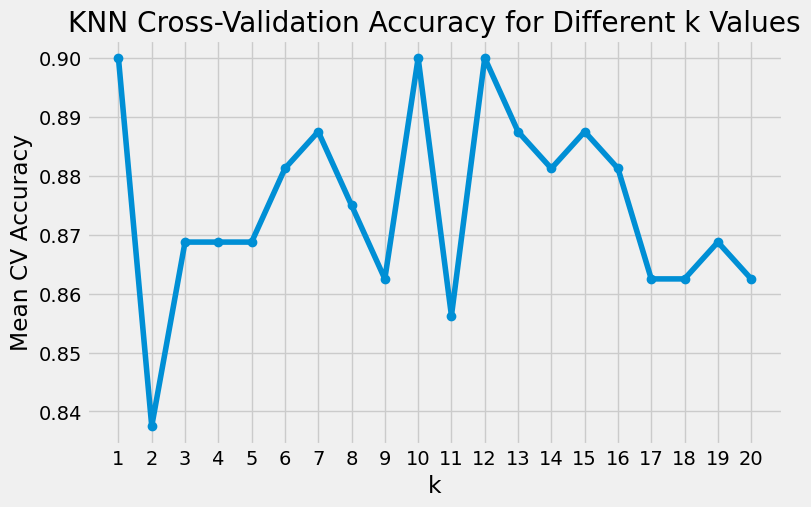

Best k (with highest mean CV accuracy): 9


In [29]:
k_range = range(1, 21)
cv_scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

plt.figure(figsize=(8, 5))
plt.plot(k_range, cv_scores, marker='o')
plt.xlabel('k')
plt.ylabel('Mean CV Accuracy')
plt.title('KNN Cross-Validation Accuracy for Different k Values')
plt.xticks(k_range)
plt.grid(True)
plt.show()

best_k = k_range[np.argmax(cv_scores[1:])]
print(f"Best k (with highest mean CV accuracy): {best_k}")

KNN | Train Accuracy: 0.906
KNN | Test Accuracy: 0.925
KNN | Recall: 0.800
KNN | Precision: 0.757
KNN | F1 Score: 0.776

Classification Report (KNN):

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        18
           1      0.786     1.000     0.880        11
           2      1.000     1.000     1.000         5
           3      0.000     0.000     0.000         3
           4      1.000     1.000     1.000         3

    accuracy                          0.925        40
   macro avg      0.757     0.800     0.776        40
weighted avg      0.866     0.925     0.892        40



c:\Users\ahmad\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ahmad\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ahmad\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\ahmad\anaconda3\Lib\site-packag

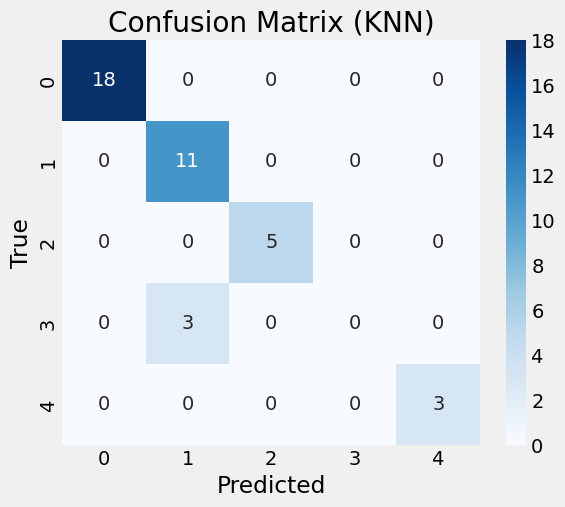

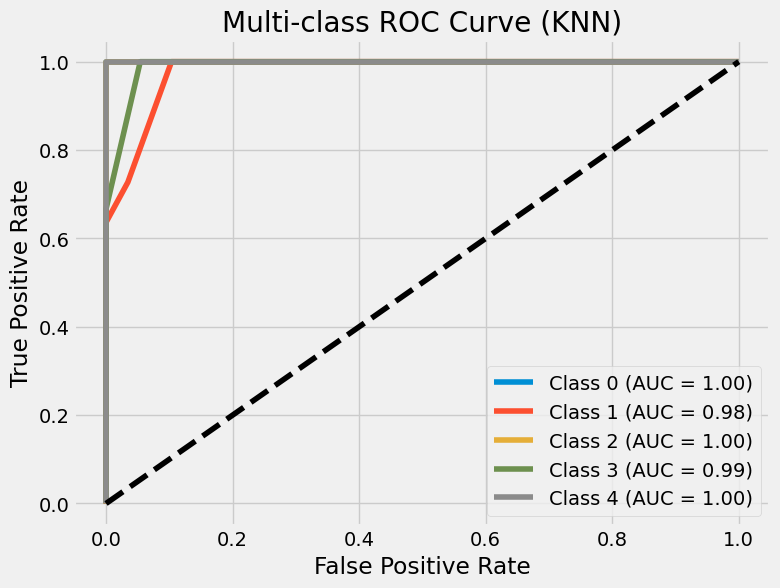

In [30]:
classification_full_eval(KNeighborsClassifier(n_neighbors=11), X_train, X_test, y_train, y_test, y, model_name='KNN')

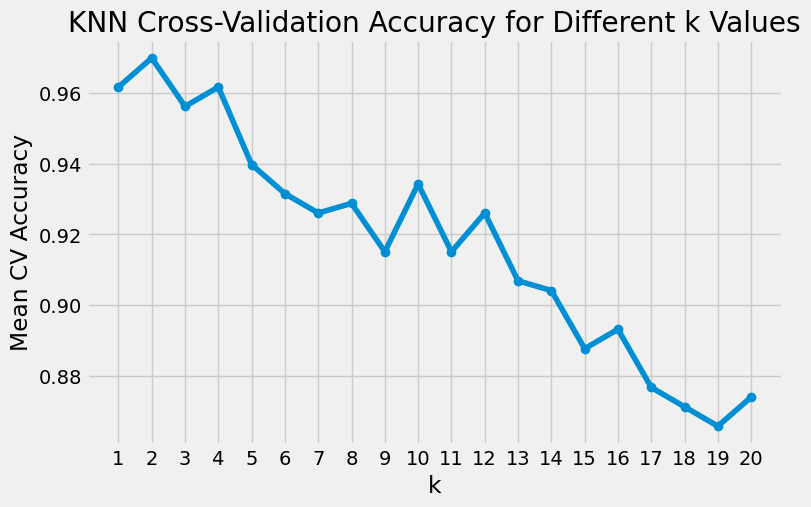

Best k (with highest mean CV accuracy): 1


In [31]:
k_range = range(1, 21)
cv_scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_resampled, y_train_resampled, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

plt.figure(figsize=(8, 5))
plt.plot(k_range, cv_scores, marker='o')
plt.xlabel('k')
plt.ylabel('Mean CV Accuracy')
plt.title('KNN Cross-Validation Accuracy for Different k Values')
plt.xticks(k_range)
plt.show()

best_k = k_range[np.argmax(cv_scores[1:])]
print(f"Best k (with highest mean CV accuracy): {best_k}")

KNN | Train Accuracy: 0.997
KNN | Test Accuracy: 0.925
KNN | Recall: 0.904
KNN | Precision: 0.961
KNN | F1 Score: 0.926

Classification Report (KNN):

              precision    recall  f1-score   support

           0      0.895     0.944     0.919        18
           1      0.909     0.909     0.909        11
           2      1.000     1.000     1.000         5
           3      1.000     1.000     1.000         3
           4      1.000     0.667     0.800         3

    accuracy                          0.925        40
   macro avg      0.961     0.904     0.926        40
weighted avg      0.928     0.925     0.924        40



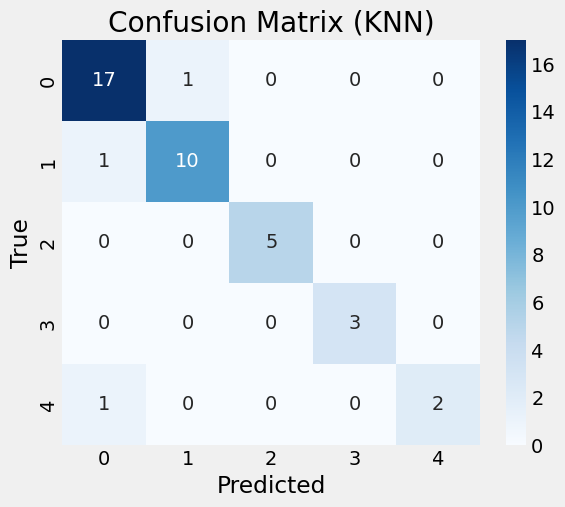

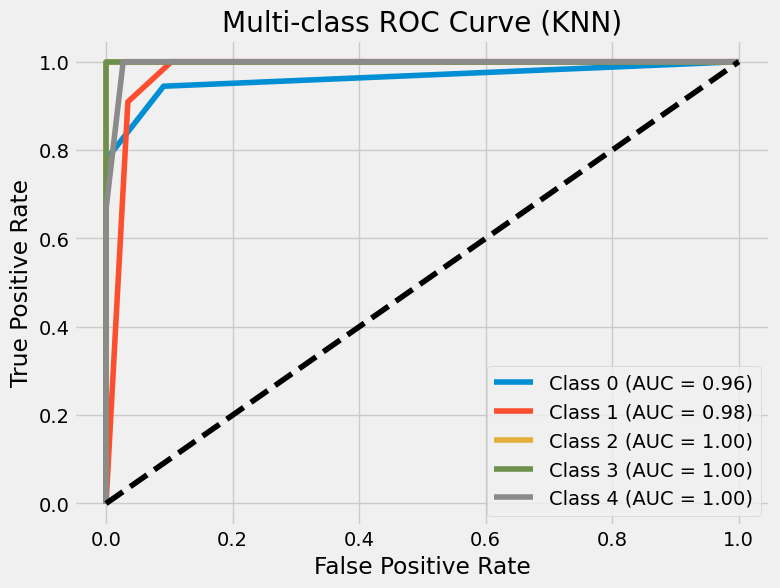

In [32]:
classification_full_eval(KNeighborsClassifier(n_neighbors=2), X_train_resampled, X_test, y_train_resampled, y_test, y, model_name='KNN')

Logistic Regression | Train Accuracy: 0.956
Logistic Regression | Test Accuracy: 0.975
Logistic Regression | Recall: 0.982
Logistic Regression | Precision: 0.989
Logistic Regression | F1 Score: 0.985

Classification Report (Logistic Regression):

              precision    recall  f1-score   support

           0      0.947     1.000     0.973        18
           1      1.000     0.909     0.952        11
           2      1.000     1.000     1.000         5
           3      1.000     1.000     1.000         3
           4      1.000     1.000     1.000         3

    accuracy                          0.975        40
   macro avg      0.989     0.982     0.985        40
weighted avg      0.976     0.975     0.975        40



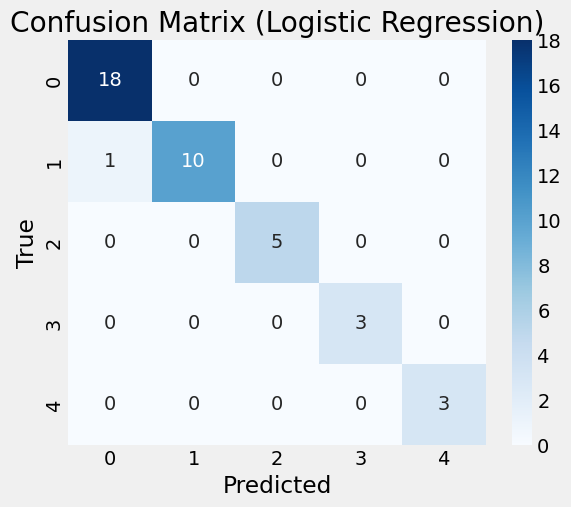

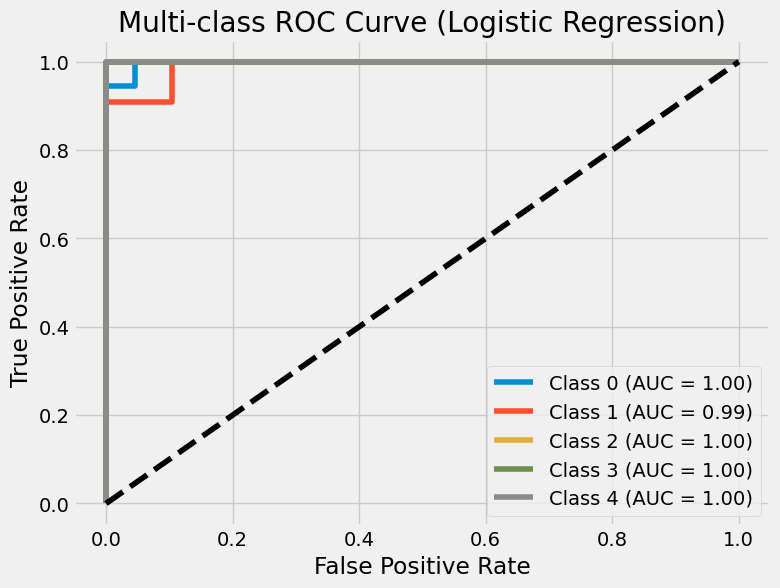

In [33]:
classification_full_eval(LogisticRegression(solver='lbfgs', max_iter=1000), X_train, X_test, y_train, y_test, y, model_name='Logistic Regression')

SVM | Train Accuracy: 0.975
SVM | Test Accuracy: 0.975
SVM | Recall: 0.982
SVM | Precision: 0.989
SVM | F1 Score: 0.985

Classification Report (SVM):

              precision    recall  f1-score   support

           0      0.947     1.000     0.973        18
           1      1.000     0.909     0.952        11
           2      1.000     1.000     1.000         5
           3      1.000     1.000     1.000         3
           4      1.000     1.000     1.000         3

    accuracy                          0.975        40
   macro avg      0.989     0.982     0.985        40
weighted avg      0.976     0.975     0.975        40



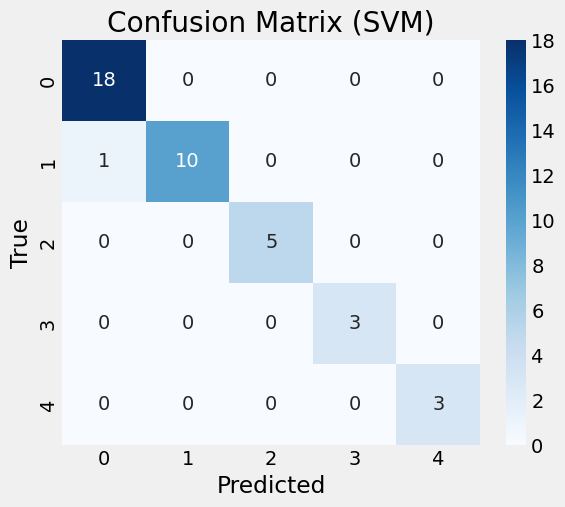

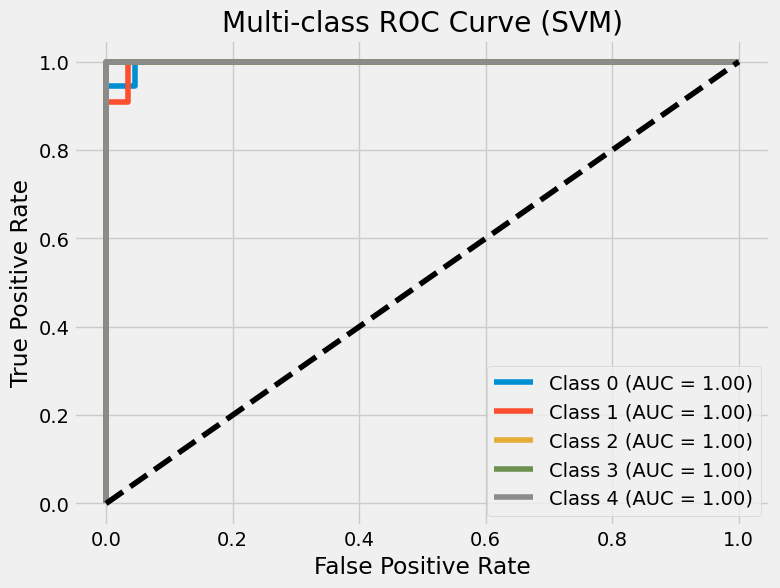

In [34]:
classification_full_eval(SVC(probability=True, kernel='rbf'), X_train, X_test, y_train, y_test, y, model_name='SVM')

In [37]:
def classification_full_eval(model, X_train, X_test, y_train, y_test, y_all, model_name='Model'):
    model.fit(X_train, y_train)
    y_test_pred = model.predict(X_test)

    acc_test = metrics.accuracy_score(y_test, y_test_pred)
    recall = metrics.recall_score(y_test, y_test_pred, average='macro')
    precision = metrics.precision_score(y_test, y_test_pred, average='macro')
    f1 = metrics.f1_score(y_test, y_test_pred, average='macro')

    n_classes = y_all.nunique()
    y_test_bin = label_binarize(y_test, classes=np.arange(n_classes))
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)
    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_test)
        if y_score.ndim == 1:
            y_score = np.vstack([1 - y_score, y_score]).T
    else:
        y_score = None
    if y_score is not None:
        auc = metrics.roc_auc_score(y_test_bin, y_score, average='macro', multi_class='ovr')
    else:
        auc = np.nan

    return {
        "model": model_name,
        "accuracy": acc_test,
        "recall": recall,
        "precision": precision,
        "f1": f1,
        "auc": auc
    }

In [38]:
results = []
for model, name in [
    (GaussianNB(), 'Naive Bayes'),
    (KNeighborsClassifier(n_neighbors=2), 'KNN'),
    (LogisticRegression(solver='lbfgs', max_iter=1000), 'Logistic Regression'),
    (SVC(probability=True, kernel='rbf'), 'SVM')
]:
    if name in ['Naive Bayes', 'KNN']:
        metrics_dict = classification_full_eval(model, X_train_resampled, X_test, y_train_resampled, y_test, y, model_name=name)
    else:
        metrics_dict = classification_full_eval(model, X_train, X_test, y_train, y_test, y, model_name=name)
    results.append(metrics_dict)

In [39]:
df_res = pd.DataFrame(results)
df_res.round(3)

,model,accuracy,recall,precision,f1,auc
0,Naive Bayes,0.950,0.949,0.900,0.915,0.994
1,KNN,0.925,0.904,0.961,0.926,0.987
2,Logistic Regression,0.975,0.982,0.989,0.985,0.998
3,SVM,0.975,0.982,0.989,0.985,0.999


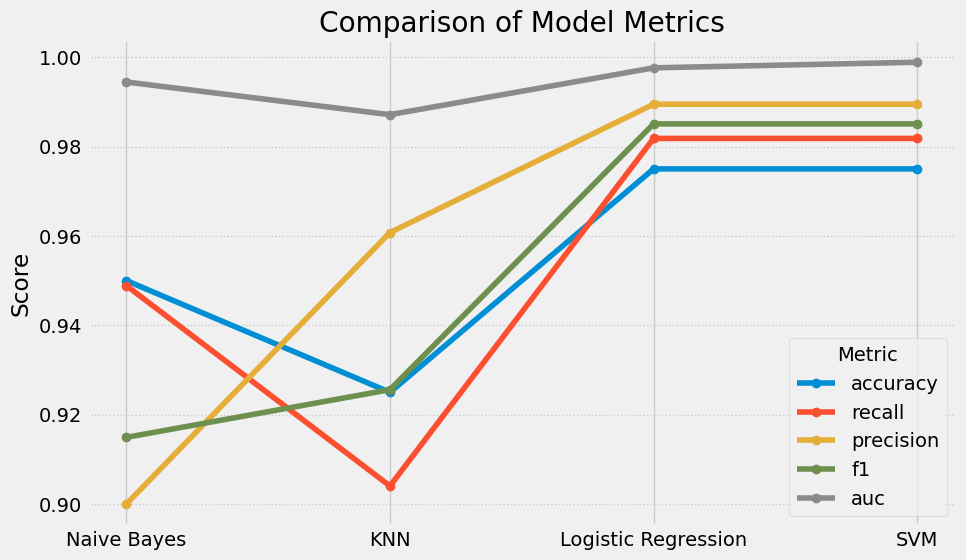

In [40]:
df_res.plot(kind='line', marker='o', figsize=(10, 6))
plt.title('Comparison of Model Metrics')
plt.ylabel('Score')
plt.legend(title='Metric')
plt.grid(axis='y', linestyle=':')
plt.xticks(ticks=range(len(df_res)), labels=df_res['model'], rotation=0)
plt.show()